### **Name**: Mohammed Feras Sawab
---
### **ID**: 2240009066
---

# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

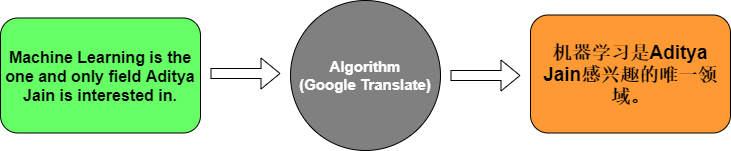

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.0000e+00 - loss: 2.4871


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.0000e+00 - loss: 2.4871 - val_accuracy: 0.0000e+00 - val_loss: 2.4869


Epoch 2/50



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1429 - loss: 2.4794

...


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7143 - loss: 0.6911


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.7143 - loss: 0.6911 - val_accuracy: 0.0000e+00 - val_loss: 4.1135



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 259ms/step - accuracy: 0.7143 - loss: 1.5414


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 267ms/step - accuracy: 0.7143 - loss: 1.5414


Test Accuracy: 0.7142857313156128


In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step


Input: How are you?
Translation: ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


**1. What does the Embedding layer do to a word index?**
It turns each integer word index into a dense vector of fixed size (here 64 numbers). The vectors are learned during training, so words that are used in similar ways end up with similar vectors. This is much better than a one-hot vector because it is small and carries meaning.

**3. What is the role of the Encoder LSTM?**
It reads the English sentence one word at a time and compresses the whole sentence into a single fixed-size vector (its final hidden state). This vector is the summary of the source sentence that is passed to the decoder.

**5. What does the Decoder LSTM do?**
It takes the summary vector from the encoder (repeated once per output position by `RepeatVector`) and generates the French sentence step by step, producing one hidden state for each output position. Each of these states is then turned into a word by the final Dense layer.

**8. Why do we use softmax in the final layer?**
Softmax converts the raw scores for every French word in the vocabulary into probabilities that are between 0 and 1 and sum to 1. This lets us pick the most likely word at each position with `argmax`, and it is the output that `sparse_categorical_crossentropy` expects when training.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [8]:
import pandas as pd
import numpy as np
import re
import kagglehub

# Download the English-French dataset from Kaggle
path = kagglehub.dataset_download("devicharith/language-translation-englishfrench")
df = pd.read_csv(f"{path}/eng_-french.csv")
df.columns = ["english", "french"]
print(df.shape)
df.head()

/Users/firas/miniconda3/envs/default/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(175621, 2)


,english,french
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


In [9]:
# Basic exploration
print(df.isnull().sum())
print(f"Duplicate pairs: {df.duplicated().sum()}")
df["en_len"] = df["english"].astype(str).str.split().str.len()
df["fr_len"] = df["french"].astype(str).str.split().str.len()
df[["en_len", "fr_len"]].describe()

english    0
french     0
dtype: int64
Duplicate pairs: 0


,en_len,fr_len
count,175621.000000,175621.000000
mean,6.161552,6.706669
std,2.485664,2.789074
min,1.000000,1.000000
25%,4.000000,5.000000
50%,6.000000,6.000000
75%,7.000000,8.000000
max,44.000000,55.000000


In [10]:
# Cleaning: drop missing/duplicate rows, lowercase, separate punctuation from words
def clean(text):
    text = str(text).lower().strip()
    text = re.sub(r"([?.!,])", r" \1 ", text)   # keep punctuation as its own token
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df = df.dropna().drop_duplicates()
df["english"] = df["english"].apply(clean)
df["french"] = df["french"].apply(clean)

# The full dataset (175k pairs) is too big for a simple LSTM on a laptop:
# keep short sentences and a random sample of them
df = df[(df["en_len"] <= 6) & (df["fr_len"] <= 8)]
df = df.sample(n=20000, random_state=42).reset_index(drop=True)
print(df.shape)
df[["english", "french"]].head(10)

(20000, 4)


,english,french
0,do you have a dog ?,as-tu un chien ?
1,he asked me to .,il me l'a demandé .
2,she advises me on technical matters .,elle me conseille sur les questions techniques .
3,i'll never be that famous .,je ne serai jamais aussi connu .
4,i know why you did it .,je sais pourquoi tu l'as fait .
5,he was leaving then .,il était alors en train de partir .
6,we need a plan .,nous avons besoin d'un plan .
7,the process is totally automated .,le processus est complètement automatisé .
8,you should follow tom's example .,vous devriez suivre l'exemple de tom .
9,i don't fear death .,je n'ai pas peur de la mort .


In [11]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

english_sentences = df["english"].tolist()
french_sentences = df["french"].tolist()

tokenizer_eng = Tokenizer(filters="")
tokenizer_eng.fit_on_texts(english_sentences)
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences)

tokenizer_frn = Tokenizer(filters="")
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

eng_vocab = len(tokenizer_eng.word_index) + 1
frn_vocab = len(tokenizer_frn.word_index) + 1
print(f"English vocabulary: {eng_vocab}, French vocabulary: {frn_vocab}")

# Pad: inputs at the start (like the lab), targets at the end so the sentence starts at position 0
eng_padded = pad_sequences(eng_sequences)
frn_padded = pad_sequences(frn_sequences, padding="post")
print(eng_padded.shape, frn_padded.shape)

English vocabulary: 5709, French vocabulary: 9744
(20000, 10) (20000, 12)


In [12]:
from sklearn.model_selection import train_test_split

eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=eng_vocab, output_dim=128),
    tf.keras.layers.LSTM(256),                                   # encoder
    tf.keras.layers.RepeatVector(frn_padded.shape[1]),
    tf.keras.layers.LSTM(256, return_sequences=True),            # decoder
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(frn_vocab, activation="softmax"))
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.build(input_shape=(None, eng_padded.shape[1]))
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 10, 128)        │       730,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 12, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 12, 256)        │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 12, 9744)       │     2,504,208 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,154,512 (15.85 MB)

 Trainable params: 4,154,512 (15.85 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
history = model.fit(eng_train, np.expand_dims(frn_train, -1),
                    epochs=15, batch_size=128, validation_split=0.1)

loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f"Test Accuracy: {accuracy:.4f}  (counts the padding positions too)")

# Accuracy on real words only, ignoring padding
pred = np.argmax(model.predict(eng_test), axis=-1)
mask = frn_test != 0
print(f"Test Accuracy (non-pad words only): {(pred[mask] == frn_test[mask]).mean():.4f}")

Epoch 1/15



  1/113 ━━━━━━━━━━━━━━━━━━━━ 3:25 2s/step - accuracy: 6.5104e-04 - loss: 9.1845


  2/113 ━━━━━━━━━━━━━━━━━━━━ 24s 222ms/step - accuracy: 0.2549 - loss: 9.1802  


  3/113 ━━━━━━━━━━━━━━━━━━━━ 24s 224ms/step - accuracy: 0.3357 - loss: 9.1738


  4/113 ━━━━━━━━━━━━━━━━━━━━ 24s 221ms/step - accuracy: 0.3783 - loss: 9.1608

...


121/125 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


123/125 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


125/125 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step


Test Accuracy (non-pad words only): 0.1771


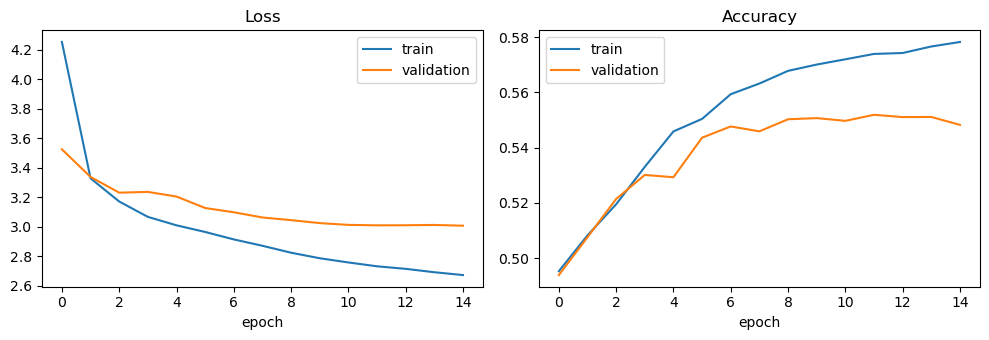

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history.history["loss"], label="train")
ax[0].plot(history.history["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train")
ax[1].plot(history.history["val_accuracy"], label="validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout()
plt.show()

In [15]:
def translate(sentence):
    sequence = tokenizer_eng.texts_to_sequences([clean(sentence)])
    padded = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted = np.argmax(model.predict(padded, verbose=0), axis=-1)[0]
    words = [tokenizer_frn.index_word[i] for i in predicted if i != 0]
    return " ".join(words)

# Sentences from the test set (reference vs. prediction)
for i in range(8):
    en = tokenizer_eng.sequences_to_texts([eng_test[i]])[0]
    fr = tokenizer_frn.sequences_to_texts([frn_test[i]])[0]
    print(f"English  : {en}\nReference: {fr}\nModel    : {translate(en)}\n")

# Product-style sentences for the e-commerce use case
for s in ["I like it.", "Where is my order?", "This is too expensive.", "Thank you."]:
    print(f"{s}  ->  {translate(s)}")

English  : i'm not a singer .
Reference: je ne suis pas un chanteur .
Model    : je ne pas pas de .

English  : you've told me that already .
Reference: tu m'as déjà dit ça .
Model    : je ne pas pas de . .

English  : they all changed .
Reference: ils ont tous changé .
Model    : je est pas . .

English  : we're starved .
Reference: nous sommes affamés .
Model    : je êtes . .

English  : you must do it .
Reference: vous devez le faire .
Model    : je est pas . .

English  : i wanted sympathy .
Reference: je voulais de la compassion .
Model    : je est . . .

English  : everything is all arranged .
Reference: tout est arrangé .
Model    : je ne pas pas . .



English  : who's winning ?
Reference: qui gagne ?
Model    : pourquoi est ? ?

I like it.  ->  c'est ! .
Where is my order?  ->  est-ce est ? ?
This is too expensive.  ->  je est est . .
Thank you.  ->  c'est ! .
